# Lab: 2D Convolution, noise removal, image smoothing


## Goal of this lab

Getting familiar with 2D convolution and convolution filters:

* Defining convolution filters
* Applying convolution filters to an image
* Smoothing images (removing additive Gaussian noise)
* Median filtering (removing Salt and Pepper noise)

Required packages

* numpy
* matplotlib
* scipy
* imageio

## Required reading
* https://github.com/scikit-image/skimage-tutorials/blob/master/lectures/1_image_filters.ipynb

You can execute individual code blocks by pressing SHIFT+Enter consecutively.

You can trigger auto completion with TABULATOR


## Import required packages

In [1]:
import numpy as np
import scipy
from scipy import ndimage
import matplotlib.pyplot as plt
from scipy import signal
import imageio.v2 as imageio

## Provided Functions

In [2]:
def gauss2D(shape=(3,3),sigma=0.5):
    m,n = [(ss-1.)/2. for ss in shape]
    y,x = np.ogrid[-m:m+1,-n:n+1]
    h = np.exp( -(x*x + y*y) / (2.*sigma*sigma) )
    h[ h < np.finfo(h.dtype).eps*h.max() ] = 0
    sumh = h.sum()
    if sumh != 0:
        h /= sumh
    return h

def addNoiseToImage(im):
    noise = np.random.normal(0,10,im.shape)
    im_noise = im+noise
    return im_noise

## Exercise 1: Understanding filters

1. Load image "einstein.jpg" from the provided test images
2. Design a 3x3 filter that does not change the image at all (i.e. an identity filter). Print the filter.
3. Convolve the image with the filter show the result. Note: for convolution we use the function provided by the scipy.signal package: scipy.signal.convolve2d(in1, in2, mode='same', boundary='fill', fillvalue=0). See https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.convolve2d.html for more details. To be able to use the function first import package signal from scipy.
4. Design a 7x7 filter that moves all pixels to the left by 2 pixels (tip: use the function np.zeros for that and set the respective filter weight to 1 manually). Print the filter.
5. Apply it to the image and show the result
6. Design a 7x7 filter that moves all pixels to the bottom left by 2 pixels. Do this in two ways: (a) Apply two filters one after the other (one that moves the pixels to the left and one that moves the pixels downwards), (b) Create a single filter can be used to move all pixels. Print all used filters.
7. Apply both approaches to the image and plot the results

To plot the input image and the filtered result image use the following code (im_in and im_out are the input and output images):
~~~python
f, (ax1, ax2) = plt.subplots(1, 2)
ax1.imshow(im_in,cmap='gray',vmin=0,vmax=255) 
ax1.set_title('Input')
ax1.axis('off')
ax2.imshow(im_out,cmap='gray',vmin=0,vmax=255) 
ax2.set_title('Output')
ax2.axis('off')
plt.show()
~~~

Identity filter (3x3):
[[0. 0. 0.]
 [0. 1. 0.]
 [0. 0. 0.]]


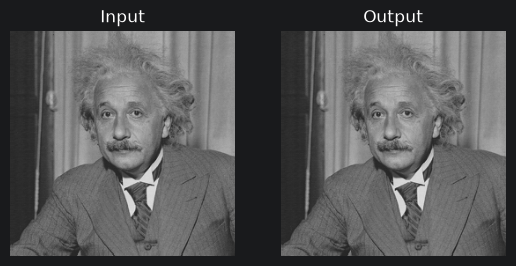

Shift-left filter (7x7):
[[0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0.]]


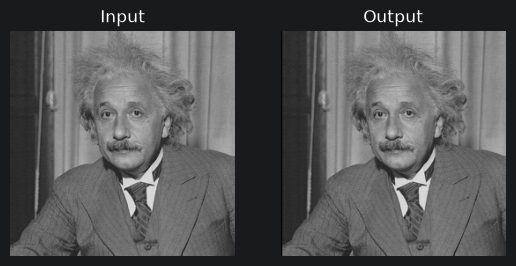

Shift-down filter (7x7):
[[0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0.]]
Shift-left filter (7x7):
[[0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0.]]
Single bottom-left filter (7x7):
[[0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 0. 0. 0.]]


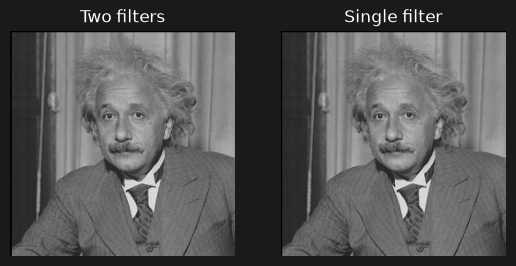

In [3]:
im = imageio.imread('../../data/test_images/einstein.jpg').astype(float)
if im.ndim == 3:
    im = im.mean(axis=2)

identity_filter = np.zeros((3, 3))
identity_filter[1, 1] = 1
print('Identity filter (3x3):')
print(identity_filter)

im_out = signal.convolve2d(im, identity_filter, mode='same', boundary='fill', fillvalue=0)

f, (ax1, ax2) = plt.subplots(1, 2)
ax1.imshow(im, cmap='gray', vmin=0, vmax=255)
ax1.set_title('Input')
ax1.axis('off')
ax2.imshow(im_out, cmap='gray', vmin=0, vmax=255)
ax2.set_title('Output')
ax2.axis('off')
plt.show()

shift_left = np.zeros((7, 7))
shift_left[3, 5] = 1
print('Shift-left filter (7x7):')
print(shift_left)

im_out = signal.convolve2d(im, shift_left, mode='same', boundary='fill', fillvalue=0)

f, (ax1, ax2) = plt.subplots(1, 2)
ax1.imshow(im, cmap='gray', vmin=0, vmax=255)
ax1.set_title('Input')
ax1.axis('off')
ax2.imshow(im_out, cmap='gray', vmin=0, vmax=255)
ax2.set_title('Output')
ax2.axis('off')
plt.show()

shift_down = np.zeros((7, 7))
shift_down[5, 3] = 1
print('Shift-down filter (7x7):')
print(shift_down)
print('Shift-left filter (7x7):')
print(shift_left)

shift_bottomleft_single = np.zeros((7, 7))
shift_bottomleft_single[5, 5] = 1
print('Single bottom-left filter (7x7):')
print(shift_bottomleft_single)

im_out_a = signal.convolve2d(im, shift_left, mode='same', boundary='fill', fillvalue=0)
im_out_a = signal.convolve2d(im_out_a, shift_down, mode='same', boundary='fill', fillvalue=0)

im_out_b = signal.convolve2d(im, shift_bottomleft_single, mode='same', boundary='fill', fillvalue=0)

f, (ax1, ax2) = plt.subplots(1, 2)
ax1.imshow(im_out_a, cmap='gray', vmin=0, vmax=255)
ax1.set_title('Two filters')
ax1.axis('off')
ax2.imshow(im_out_b, cmap='gray', vmin=0, vmax=255)
ax2.set_title('Single filter')
ax2.axis('off')
plt.show()


## Exercise 2: Understanding different modes and boundary conditions

For the boundary pixels of an image the convolution filter usually does not fit in completely. For this purpose, there are different boundary conditions and modes in the convolution. So far we used boundary condition "fill" and mode "full" (see https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.convolve2d.html for more information). 
In the following define a convolution filter that moves the image by 35 pixels up. Print the filter. Apply this filter with all the modes and boundary conditions that scipy supports. First apply all the 3 modes (with default boundary condition) and then all the three boundary conditions (with default mode). 

**Question:** Observe the results and interprete which mode and boundary condition is doing what in the markup field below. 

Possible modes are:
* full
* valid
* same

Possible boundary conditions are:
* fill
* wrap
* symm



 


Shift-up-35 filter shape: (71, 71)


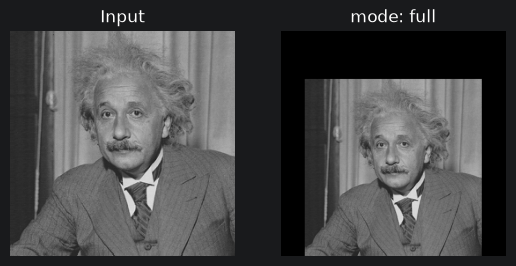

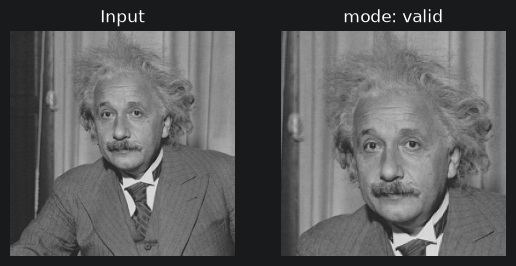

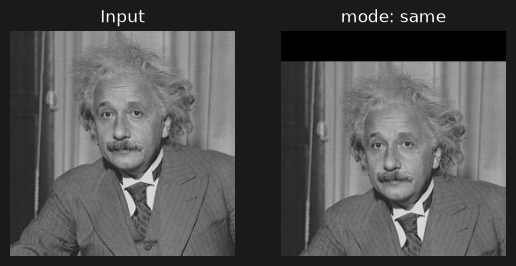

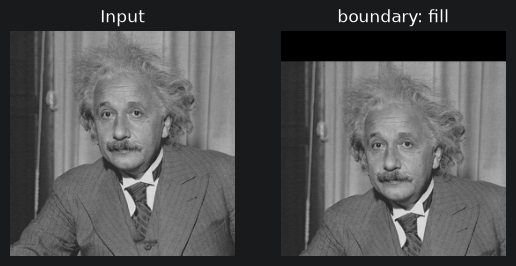

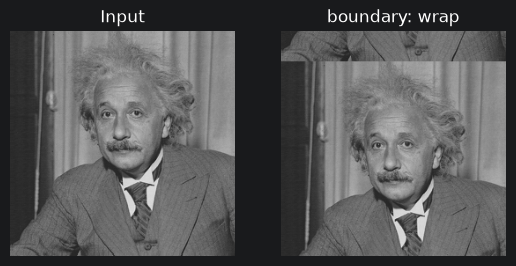

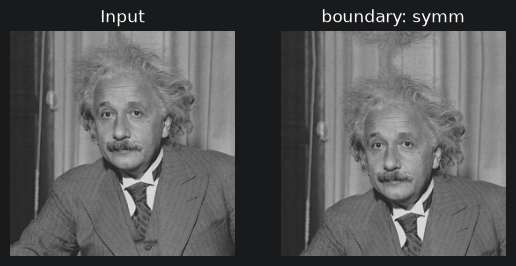

In [4]:
size = 71
center = size // 2
shift_up35 = np.zeros((size, size))
shift_up35[center + 35, center] = 1
print('Shift-up-35 filter shape:', shift_up35.shape)

for mode in ['full', 'valid', 'same']:
    im_out = signal.convolve2d(im, shift_up35, mode=mode, boundary='fill', fillvalue=0)
    f, (ax1, ax2) = plt.subplots(1, 2)
    ax1.imshow(im, cmap='gray', vmin=0, vmax=255)
    ax1.set_title('Input')
    ax1.axis('off')
    ax2.imshow(im_out, cmap='gray', vmin=0, vmax=255)
    ax2.set_title('mode: ' + mode)
    ax2.axis('off')
    plt.show()

for bc in ['fill', 'wrap', 'symm']:
    im_out = signal.convolve2d(im, shift_up35, mode='same', boundary=bc)
    f, (ax1, ax2) = plt.subplots(1, 2)
    ax1.imshow(im, cmap='gray', vmin=0, vmax=255)
    ax1.set_title('Input')
    ax1.axis('off')
    ax2.imshow(im_out, cmap='gray', vmin=0, vmax=255)
    ax2.set_title('boundary: ' + bc)
    ax2.axis('off')
    plt.show()


**Your Answer Here:**

- **full**: The output size is (N + M - 1), meaning the filter is allowed to slide fully off the image edges, padding the outside with zeros.
- **valid**: Only filter positions where the kernel lies completely within the image are computed, so the output shrinks to (N - M + 1).
- **same**: The output keeps the same dimensions as the input; what happens at the edges depends on the boundary condition.

- **fill**: Everything outside the image boundary is treated as 0 (black), so shifted regions appear as a dark strip.
- **wrap**: The image is tiled periodically, so content that disappears off one edge wraps back in from the opposite side.
- **symm**: The image is reflected at its borders, so edge pixels are mirrored outward instead of being zero-padded.

## Exercise 3: Smoothing images

1. Load image "einstein" from the provided test images
2. Add Gaussian noise to the image with function addNoiseToImage() (see below)
3. Define a 5x5 averaging filter and apply it to the image, show the result (Note: the averaging filters can be generated by creating a 5x5 numpy array of ones (function np.ones) and then dividing by the number of elements in the filter (5*5 for a 5x5 filter). Print the filter.
4. Define a 5x5 Gaussian filter (with the provided function gauss2D(), see below) to the image. Use a sigma of 1.0. Apply it to the image and show the result. Print the filter.
**Question:** Which filter removes the noise better? Which filter preserves the original image better. Play around with different sigmas for the Gaussian kernel and with different filter sizes for the averaging filter. How does it change the result?


**Your Answer Here:**

The Gaussian filter does a better job of preserving edges and fine details compared to the averaging filter. This is because it gives higher weight to nearby pixels and less weight to distant ones, whereas the box filter weights every pixel in the window equally, which smears edges even more. Making the sigma larger or the kernel bigger both increase the amount of smoothing and noise suppression, but at the cost of more detail loss.

Averaging filter (5x5):
[[0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]]


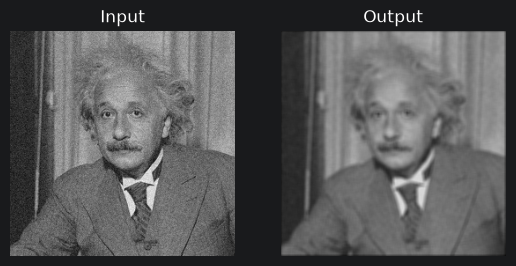

Gaussian filter (5x5, sigma=1.0):
[[0.00296902 0.01330621 0.02193823 0.01330621 0.00296902]
 [0.01330621 0.0596343  0.09832033 0.0596343  0.01330621]
 [0.02193823 0.09832033 0.16210282 0.09832033 0.02193823]
 [0.01330621 0.0596343  0.09832033 0.0596343  0.01330621]
 [0.00296902 0.01330621 0.02193823 0.01330621 0.00296902]]


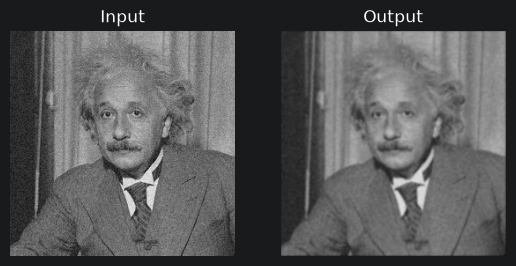

In [5]:
im = imageio.imread('../../data/test_images/einstein.jpg').astype(float)
if im.ndim == 3:
    im = im.mean(axis=2)

im_noisy = addNoiseToImage(im)

avg_filter = np.ones((5, 5)) / (5 * 5)
print('Averaging filter (5x5):')
print(avg_filter)

im_out = signal.convolve2d(im_noisy, avg_filter, mode='same', boundary='fill', fillvalue=0)

f, (ax1, ax2) = plt.subplots(1, 2)
ax1.imshow(im_noisy, cmap='gray', vmin=0, vmax=255)
ax1.set_title('Input')
ax1.axis('off')
ax2.imshow(im_out, cmap='gray', vmin=0, vmax=255)
ax2.set_title('Output')
ax2.axis('off')
plt.show()

gauss_filter = gauss2D(shape=(5, 5), sigma=1.0)
print('Gaussian filter (5x5, sigma=1.0):')
print(gauss_filter)

im_out = signal.convolve2d(im_noisy, gauss_filter, mode='same', boundary='fill', fillvalue=0)

f, (ax1, ax2) = plt.subplots(1, 2)
ax1.imshow(im_noisy, cmap='gray', vmin=0, vmax=255)
ax1.set_title('Input')
ax1.axis('off')
ax2.imshow(im_out, cmap='gray', vmin=0, vmax=255)
ax2.set_title('Output')
ax2.axis('off')
plt.show()


## Exersice 4: Median filter for removing Salt and Pepper noise

1. Load image "SaltAndPepper.gif" from the provided test images
2. Apply the Gaussian filter and the average filter from the previous task to the image, show the result. **Question:** Could the noise be removed? Did the situation even get worse?
3. Apply a median filter of Size 3x3 to the image and show the result. See https://docs.scipy.org/doc/scipy-0.16.1/reference/generated/scipy.ndimage.filters.median_filter.html for how to use a median filter.
4. **Question:** Can the median filter remove the noise? Play around with different filter sizes. Which filter size is optimal? What happens if the filter size becomes too large? Which artifacts appear?
    

**Your Answers Here:**

**Question 2:** No, neither filter removes the noise cleanly. Because salt-and-pepper noise consists of extreme values (pure black or white), convolving with a linear filter just dilutes those extremes into neighboring pixels rather than eliminating them. The result is blurry and still visibly corrupted.

**Question 4:** Yes, the median filter handles this noise well. In any small neighborhood the extreme outlier pixels are in the minority, so they get pushed out by the median operation. A 3x3 kernel is already sufficient and gives the best trade-off. Larger kernels remove the noise more aggressively but start smearing fine structures and producing a blocky, posterized look.

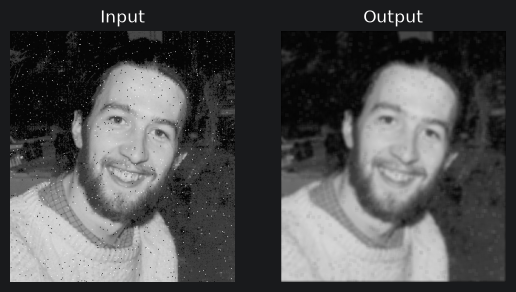

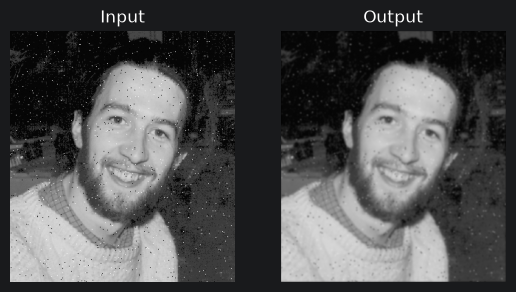

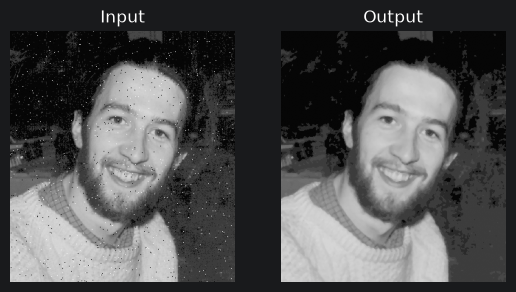

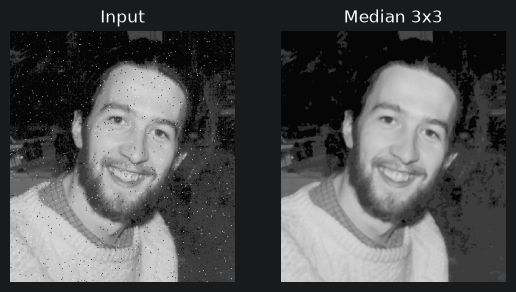

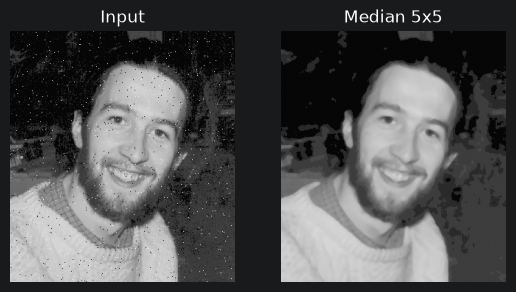

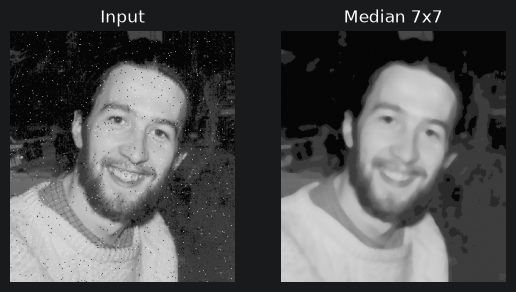

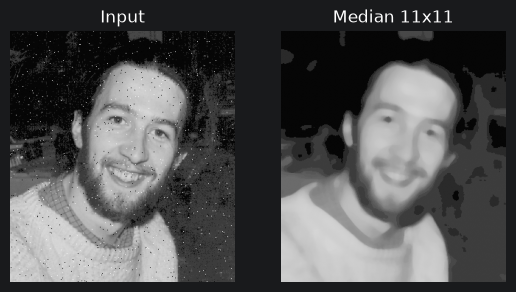

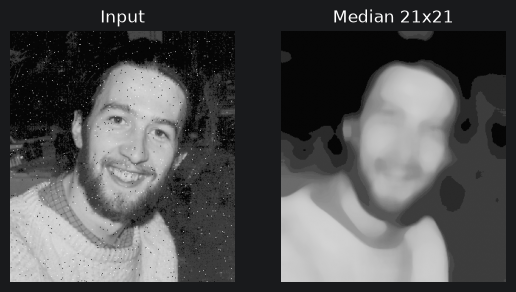

In [6]:
im_sp = imageio.imread('../../data/test_images/SaltAndPepper.gif').astype(float)
if im_sp.ndim == 3:
    im_sp = im_sp.mean(axis=2)

im_out = signal.convolve2d(im_sp, avg_filter, mode='same', boundary='fill', fillvalue=0)

f, (ax1, ax2) = plt.subplots(1, 2)
ax1.imshow(im_sp, cmap='gray', vmin=0, vmax=255)
ax1.set_title('Input')
ax1.axis('off')
ax2.imshow(im_out, cmap='gray', vmin=0, vmax=255)
ax2.set_title('Output')
ax2.axis('off')
plt.show()

im_out = signal.convolve2d(im_sp, gauss_filter, mode='same', boundary='fill', fillvalue=0)

f, (ax1, ax2) = plt.subplots(1, 2)
ax1.imshow(im_sp, cmap='gray', vmin=0, vmax=255)
ax1.set_title('Input')
ax1.axis('off')
ax2.imshow(im_out, cmap='gray', vmin=0, vmax=255)
ax2.set_title('Output')
ax2.axis('off')
plt.show()

im_out = ndimage.median_filter(im_sp, size=3)

f, (ax1, ax2) = plt.subplots(1, 2)
ax1.imshow(im_sp, cmap='gray', vmin=0, vmax=255)
ax1.set_title('Input')
ax1.axis('off')
ax2.imshow(im_out, cmap='gray', vmin=0, vmax=255)
ax2.set_title('Output')
ax2.axis('off')
plt.show()

for s in [3, 5, 7, 11, 21]:
    im_out = ndimage.median_filter(im_sp, size=s)
    f, (ax1, ax2) = plt.subplots(1, 2)
    ax1.imshow(im_sp, cmap='gray', vmin=0, vmax=255)
    ax1.set_title('Input')
    ax1.axis('off')
    ax2.imshow(im_out, cmap='gray', vmin=0, vmax=255)
    ax2.set_title('Median ' + str(s) + 'x' + str(s))
    ax2.axis('off')
    plt.show()
